In [1]:
import matplotlib.pyplot as plt
plt.style.use("default")

In [3]:
import torch
import torchvision

In [23]:
class IsingDenoiser:

    def __init__(self, image_path, sigma=1.5, lambda_=1.0, device=None):

        # dispositivo
        self.device = device if device else ("cuda" if torch.cuda.is_available() else "cpu")

        # parámetros
        self.sigma = sigma
        self.sigma2 = sigma**2
        self.lambda_ = lambda_

        # ----------------------------
        # imagen (CPU)
        # ----------------------------
        image = torchvision.io.read_image(
            image_path,
            mode=torchvision.io.ImageReadMode.GRAY
        ).float()

        image = image / image.max()
        image = torch.sign(image - 0.5)

        self.image = image[0]

        # ----------------------------
        # ruido (CPU)
        # ----------------------------
        noise = torch.randn_like(self.image) * sigma
        self.noise_image = self.image + noise

        # versión GPU (solo una vez)
        self.noise_image_gpu = self.noise_image.to(self.device)

        self.H, self.W = self.image.shape

        # ----------------------------
        # kernel (🔥 fijo en GPU)
        # ----------------------------
        self.kernel = torch.tensor([
            [0, 1, 0],
            [1, 0, 1],
            [0, 1, 0]
        ], dtype=torch.float32, device=self.device).unsqueeze(0).unsqueeze(0)

    # --------------------------------------------------
    # vecinos (GPU)
    # --------------------------------------------------
    def neighbor_sum_all(self, x):

        x = x.unsqueeze(0).unsqueeze(0)
        S = torch.nn.functional.conv2d(x, self.kernel, padding=1)

        return S[0, 0]

    # --------------------------------------------------
    # Sequential MH (checkerboard)
    # --------------------------------------------------
    def sequential_mh(self, N=50000, save_every=100):

        theta = torch.ones_like(self.noise_image_gpu)

        i = torch.arange(self.H, device=self.device).view(-1, 1)
        j = torch.arange(self.W, device=self.device).view(1, -1)

        mask_black = (i + j) % 2 == 0
        mask_white = ~mask_black

        Theta = []

        with torch.no_grad():

            for t in range(N):

                # negros
                S = self.neighbor_sum_all(theta)
                logit = 2 * (self.lambda_ * S + self.noise_image_gpu / self.sigma2)
                logit.clamp_(-10, 10)
                p = torch.sigmoid(logit)

                u = torch.rand_like(theta)
                theta[mask_black] = torch.where(u < p, 1., -1.)[mask_black]

                # blancos
                S = self.neighbor_sum_all(theta)
                logit = 2 * (self.lambda_ * S + self.noise_image_gpu / self.sigma2)
                logit.clamp_(-10, 10)
                p = torch.sigmoid(logit)

                u = torch.rand_like(theta)
                theta[mask_white] = torch.where(u < p, 1., -1.)[mask_white]

                # guardar cada k pasos en CPU
                if t % save_every == 0:
                    Theta.append(theta.detach().cpu().clone())

        return Theta

    # --------------------------------------------------
    # Random Scan MH (CPU)
    # --------------------------------------------------
    def random_scan_mh(self, N=200000, save_every=100):

        theta = torch.ones_like(self.noise_image)
        Theta = []

        with torch.no_grad():

            for t in range(N):

                i = torch.randint(0, self.H, (1,)).item()
                j = torch.randint(0, self.W, (1,)).item()

                S = 0
                if i > 0: S += theta[i-1, j]
                if i < self.H - 1: S += theta[i+1, j]
                if j > 0: S += theta[i, j-1]
                if j < self.W - 1: S += theta[i, j+1]

                logit = 2 * (self.lambda_ * S + self.noise_image[i, j] / self.sigma2)
                logit = torch.clamp(logit, -10, 10)
                p = torch.sigmoid(logit)

                theta[i, j] = 1. if torch.rand(1) < p else -1.

                if t % save_every == 0:
                    Theta.append(theta.clone())

        return Theta

    # --------------------------------------------------
    # Plot (🔥 estilo original adaptado)
    # --------------------------------------------------
    def plot_results(self, Theta, iters, save_every):

        for j in iters:

            idx = j // save_every  # 🔥 conversión clave

            if idx >= len(Theta):
                continue

            fig, axes = plt.subplots(1, 3, figsize=(12, 4))

            axes[0].imshow(self.image.numpy(), cmap='gray')
            axes[0].set_title("Imagen Verdadera")
            axes[0].axis('off')

            axes[1].imshow(self.noise_image.numpy(), cmap='gray')
            axes[1].set_title("Imagen con Ruido")
            axes[1].axis('off')

            axes[2].imshow(Theta[idx].numpy(), cmap='gray')
            axes[2].set_title("Imagen Simulada")
            axes[2].axis('off')

            plt.tight_layout(rect=[0, 0, 1, 0.90])
            fig.suptitle(f'n = {j+1}')  # 👈 igual que tu versión

            plt.show()

In [24]:
model = IsingDenoiser("riceImage.png", sigma=1.5, lambda_=1.0)

In [14]:
#Sequential (GPU)
Theta_seq = model.sequential_mh(N=50000, save_every=200)


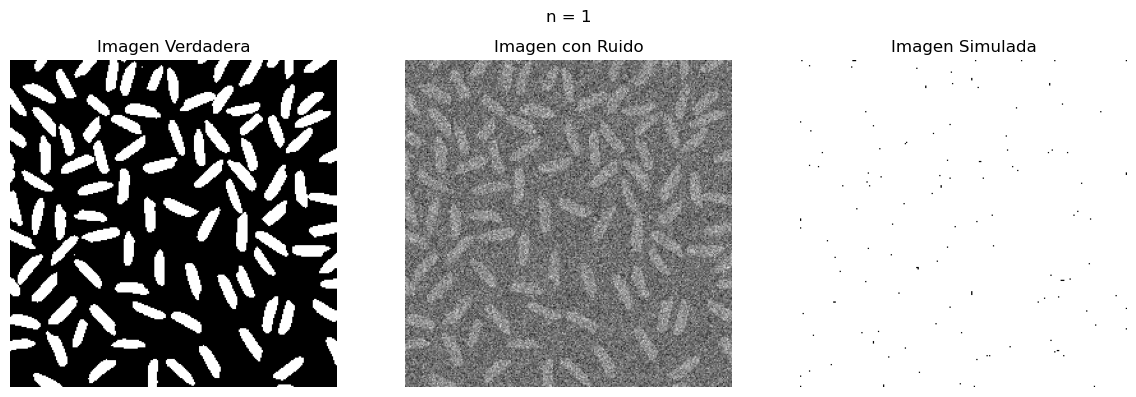

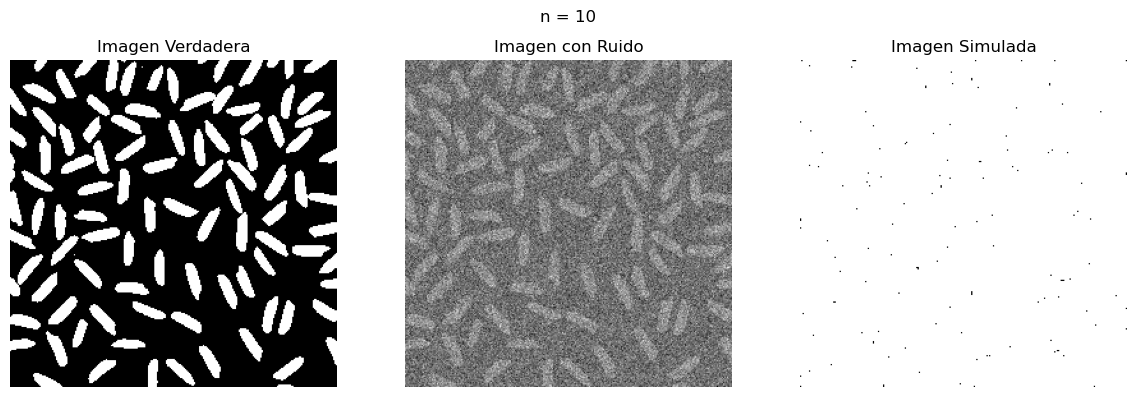

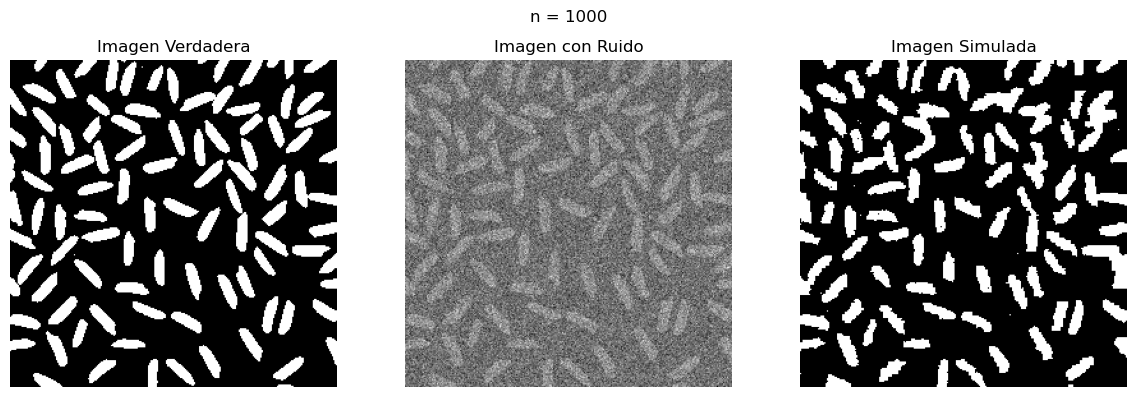

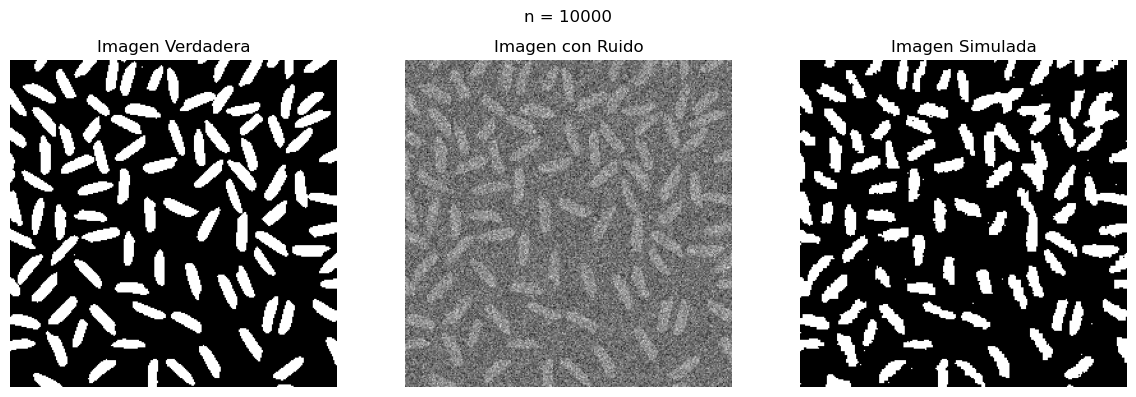

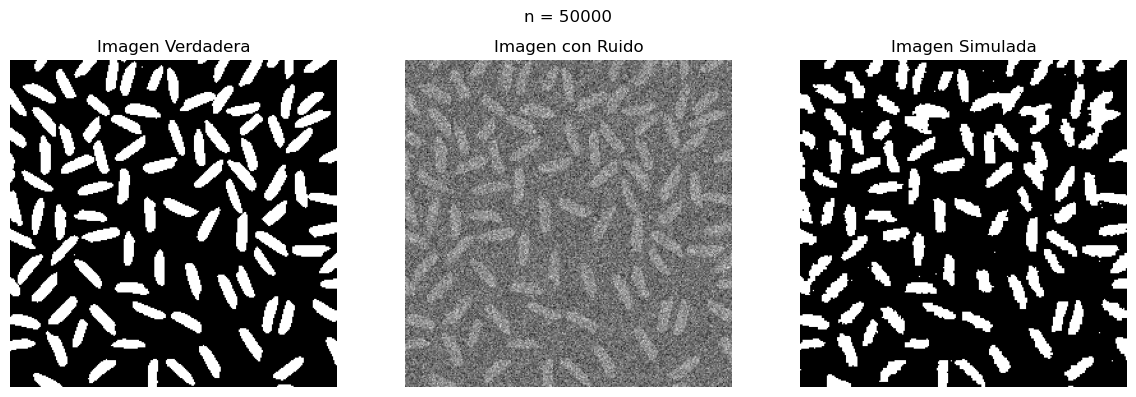

In [17]:
model.plot_results(
    Theta_seq,
    iters=[0, 9, 999, 9999, 49999],
    save_every=200
)

In [29]:
save_every = 100000  # 🔥 importante (random scan necesita más thinning)

Theta_rand = model.random_scan_mh(
    N=5000000,
    save_every=save_every
)

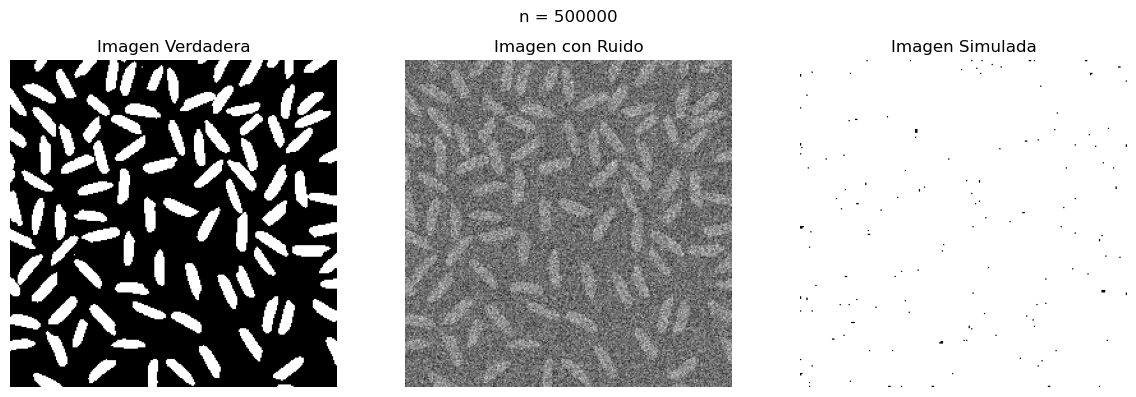

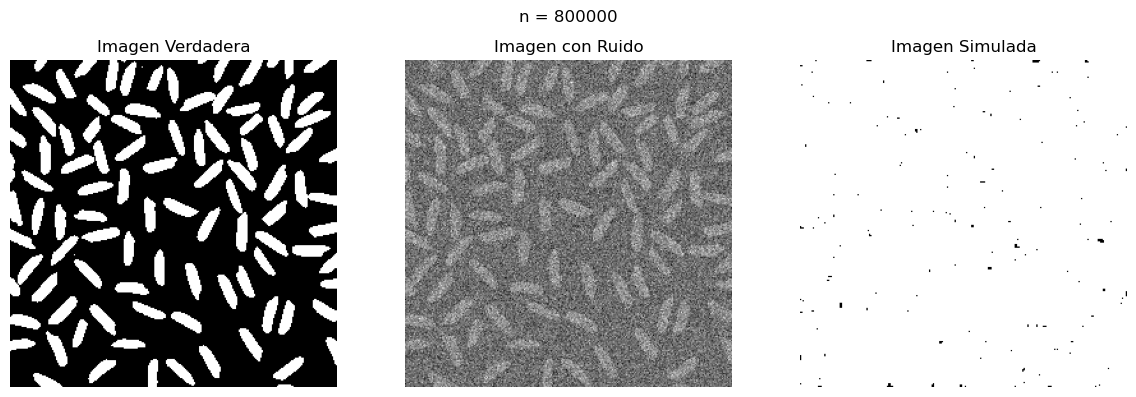

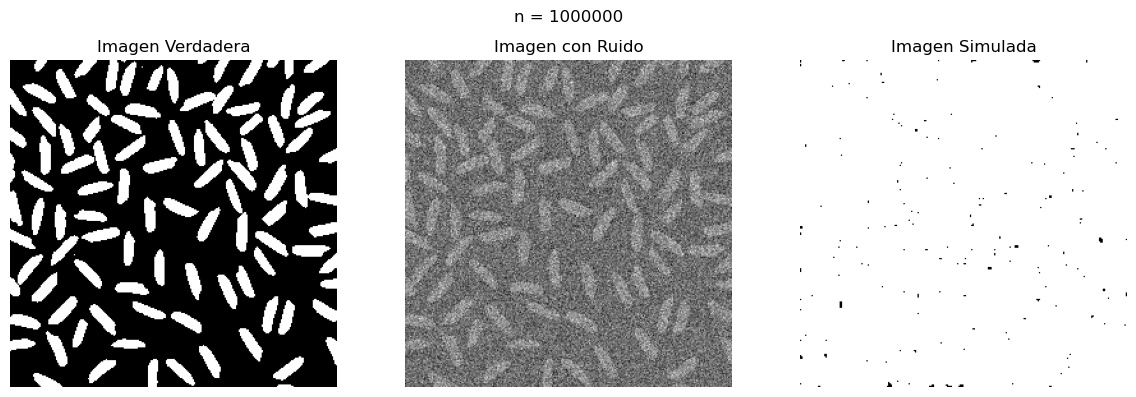

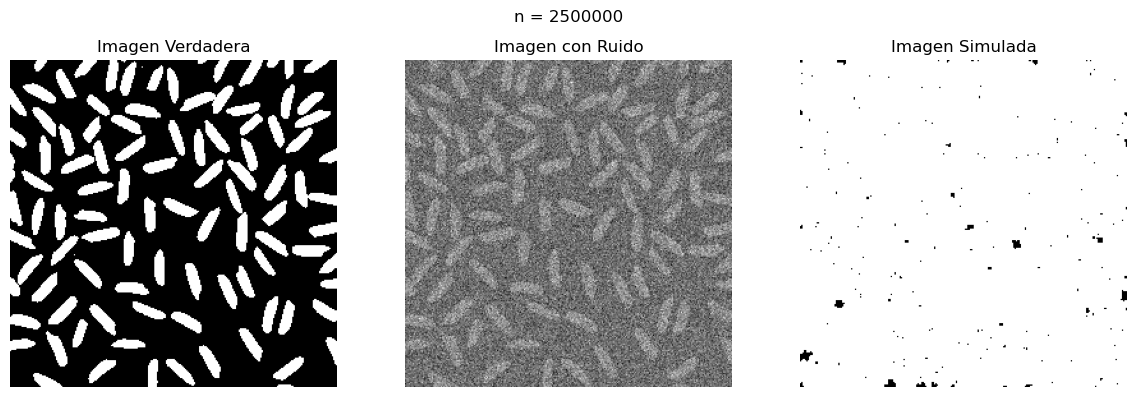

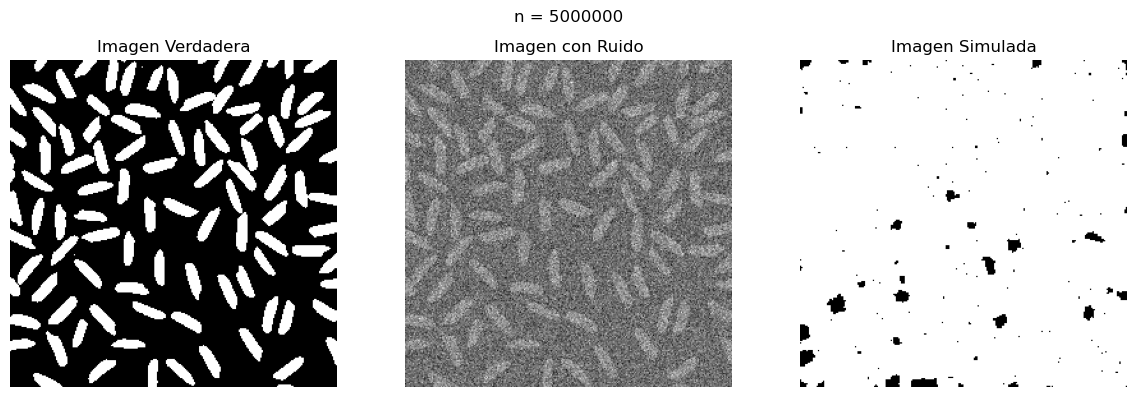

In [30]:
iters = [499999, 799999, 999999, 2499999, 4999999]

model.plot_results(
    Theta_rand,
    iters,
    save_every
)

In [11]:
class GibbsBayesianLinearRegression():

    def __init__(self, X, y, tau=10.0, a=1e-3, b=1e-3):

        self.X = X
        self.y = y
        self.tau = tau
        self.a = a
        self.b = b
        self.n , self.d = X.shape
        self.beta_prior = torch.distributions.MultivariateNormal(torch.zeros(self.d), (tau**2)*torch.eye(self.d))
        self.sigma2_prior = torch.distributions.InverseGamma(self.a, self.b)
        self.n_iters = None
        self.burn_in = None
        self.beta_samples = None
        self.sigma2_samples = None
        self.beta = None
        self.sigma2 = None
        self.n_chains = None

    def fit(self, n_iters=100, burn_in=0, n_chains=1):

        self.n_iters = n_iters
        self.burn_in = burn_in
        self.n_chains = n_chains
        self.beta_samples = torch.empty((self.n_iters, self.n_chains, self.d))
        self.sigma2_samples = torch.empty((self.n_iters, self.n_chains))

        beta = self.beta_prior.sample((self.n_chains,))
        sigma2 = self.sigma2_prior.sample((self.n_chains,))

        XtX = self.X.mT @ self.X
        Xty = self.X.mT @ self.y

        I = torch.eye(self.d)

        for i in range(self.n_iters):

            sigma_n = (1/sigma2)

            self.beta_samples[i, :, :] = beta
            self.sigma2_samples[i, :] = sigma2

            A = XtX.unsqueeze(0) / sigma2.view(-1,1,1) + I.unsqueeze(0) / (self.tau**2)

            Sigma = torch.linalg.inv(A)
            mu = torch.matmul(Sigma, Xty.view(1,-1,1) / sigma2.view(-1,1,1)).squeeze(-1)

            eps = torch.randn((n_chains, self.d))
            L = torch.linalg.cholesky(Sigma)

            beta = mu + torch.matmul(L, eps.unsqueeze(-1)).squeeze(-1)
            resid = self.y.unsqueeze(0) - torch.matmul(self.X, beta.T).mT

            an = self.a + self.n / 2
            bn = self.b + 0.5 * torch.sum(resid**2, dim=1)

            sigma2 = torch.distributions.InverseGamma(an, bn).sample()

            if i >= burn_in:
                self.beta_samples[i] = beta
                self.sigma2_samples[i] = sigma2

        self.beta = self.beta_samples.mean(dim=(0,1))
        self.sigma2 = self.sigma2_samples.mean()

In [12]:
torch.manual_seed(42)
n = 2000
beta_true = torch.tensor([2.0, -1.5])
sigma_true = 1.0

X = torch.randn(n, 2)

epsilon = sigma_true * torch.randn(n)

y = X @ beta_true + epsilon

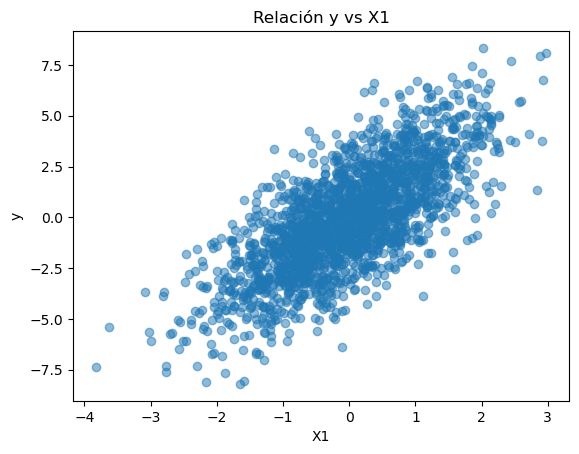

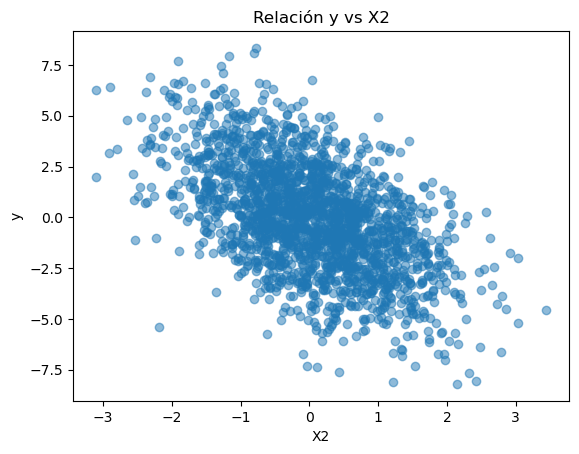

In [13]:
plt.scatter(X[:,0].numpy(), y.numpy(), alpha=0.5)
plt.title("Relación y vs X1")
plt.xlabel("X1")
plt.ylabel("y")
plt.show()

plt.scatter(X[:,1].numpy(), y.numpy(), alpha=0.5)
plt.title("Relación y vs X2")
plt.xlabel("X2")
plt.ylabel("y")
plt.show()

In [16]:
model = GibbsBayesianLinearRegression(X, y)

model.fit(
    n_iters=6000,
    burn_in=2000,
    n_chains=3
)

print("Beta estimado:", model.beta)
print("Sigma^2 estimado:", model.sigma2)

Beta estimado: tensor([ 1.9876, -1.5035])
Sigma^2 estimado: tensor(1.0596)


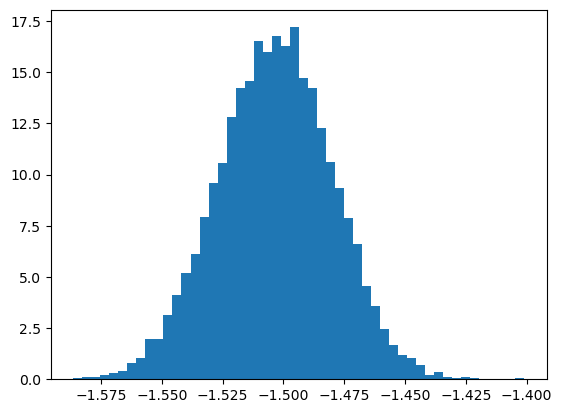

In [25]:
plt.hist(model.beta_samples[:,:,1].view(-1,1), bins=50, density=True)
plt.show()

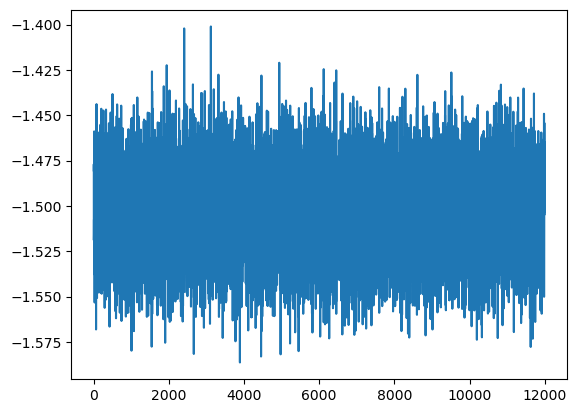

In [26]:
plt.plot(model.beta_samples[:,:,1].view(-1,1))
plt.show()

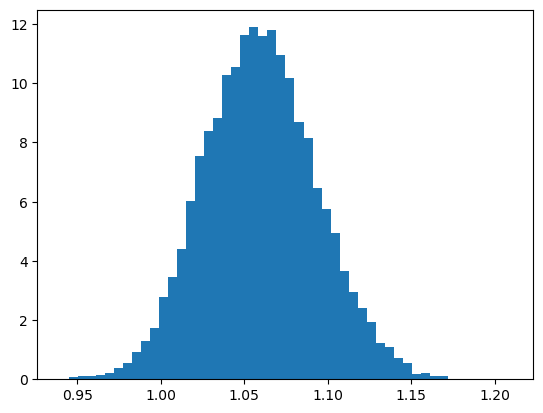

In [27]:
plt.hist(model.sigma2_samples[:,:].view(-1,1), bins=50, density=True)
plt.show()

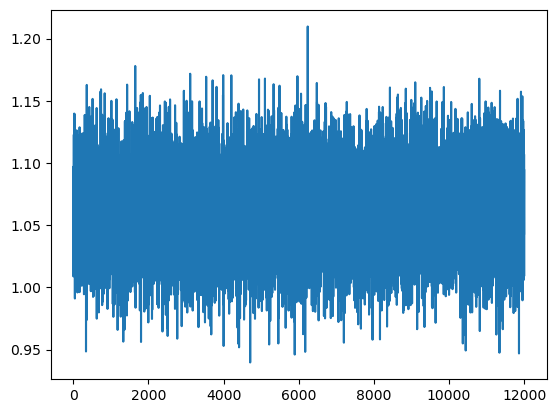

In [28]:
plt.plot(model.sigma2_samples[:,:].view(-1,1))
plt.show()